# TreeSHAP Explainability & Actuarial Ratebook Translation


In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10


FEATURE_COLS = [
    "DrivAge",
    "VehAge",
    "VehPower",
    "BonusMalus",
    "LogDensity",
    "Area",
    "VehGas",
    "VehBrand",
    "Region",
]

CATEGORICAL_COLS = ["Area", "VehGas", "VehBrand", "Region"]


def prepare_xgb_dataframe(df: pd.DataFrame, feature_cols: list[str] = None) -> pd.DataFrame:
    if feature_cols is None:
        feature_cols = FEATURE_COLS
    X = df[feature_cols].copy()
    for col in CATEGORICAL_COLS:
        if col in X.columns:
            X[col] = X[col].astype("category")
    return X


# Alias for backwards compatibility
prepare_xgb_features = prepare_xgb_dataframe


class TreeSHAPExplainer:

    def __init__(self, booster, feature_cols: list[str] = None):
        self.feature_cols = feature_cols if feature_cols is not None else FEATURE_COLS
        self.booster = booster
        self.explainer = shap.TreeExplainer(self.booster)
        self.shap_values = None
        self.explanation = None
        self.feature_data = None

    def compute_shap_values(
        self,
        df: pd.DataFrame,
        sample_size: int = 10_000,
        random_state: int = 42,
        offset_col: str = None,
    ) -> shap.Explanation:
        if len(df) > sample_size:
            sample_df = df.sample(n=sample_size, random_state=random_state)
        else:
            sample_df = df.copy()

        self.feature_data = prepare_xgb_dataframe(sample_df, self.feature_cols)
        if offset_col is not None and offset_col in sample_df.columns:
            base_margin = sample_df[offset_col].values
        else:
            base_margin = np.zeros(len(sample_df))
        dmat = xgb.DMatrix(self.feature_data, base_margin=base_margin, enable_categorical=True)
        
        # Calculate raw SHAP values via TreeExplainer
        raw_shap = self.explainer.shap_values(dmat)
        self.shap_values = raw_shap
        
        # Build standard shap.Explanation object for plotting
        expected_val = self.explainer.expected_value
        if isinstance(expected_val, (list, np.ndarray)) and len(expected_val) == 1:
            expected_val = float(expected_val[0])
            
        self.explanation = shap.Explanation(
            values=raw_shap,
            base_values=np.full(len(self.feature_data), expected_val),
            data=self.feature_data.values,
            feature_names=self.feature_cols,
        )
        return self.explanation

    def get_feature_importance_df(self) -> pd.DataFrame:
        if self.shap_values is None:
            raise ValueError("Must call compute_shap_values first.")
        
        mean_abs_shap = np.abs(self.shap_values).mean(axis=0)
        df_imp = pd.DataFrame({
            "Feature": self.feature_cols,
            "Mean_Abs_SHAP": mean_abs_shap
        }).sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
        df_imp["Relative_Importance_Pct"] = (df_imp["Mean_Abs_SHAP"] / df_imp["Mean_Abs_SHAP"].sum()) * 100
        return df_imp

def build_binned_relativities(
    df: pd.DataFrame,
    pred_glm_col: str,
    pred_xgb_col: str,
    group_col: str,
    exposure_col: str = "Exposure_Capped",
) -> pd.DataFrame:
    base_glm = np.average(df[pred_glm_col], weights=df[exposure_col])
    base_xgb = np.average(df[pred_xgb_col], weights=df[exposure_col])
    
    summary = []
    for val, grp in df.groupby(group_col, observed=True):
        exp = grp[exposure_col].sum()
        mean_glm = np.average(grp[pred_glm_col], weights=grp[exposure_col])
        mean_xgb = np.average(grp[pred_xgb_col], weights=grp[exposure_col])
        
        summary.append({
            group_col: val,
            "Policies": len(grp),
            "Exposure": exp,
            "Exposure_Pct": (exp / df[exposure_col].sum()) * 100,
            "GLM_Pure_Premium": mean_glm,
            "GLM_Relativity": mean_glm / base_glm if base_glm > 0 else 0.0,
            "XGB_Pure_Premium": mean_xgb,
            "XGB_Relativity": mean_xgb / base_xgb if base_xgb > 0 else 0.0,
        })
        
    return pd.DataFrame(summary)

def train_val_test_split(
    df: pd.DataFrame,
    test_size: float = 0.2,
    val_size: float = 0.1,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df_trainval, df_test = train_test_split(
        df, test_size=test_size, random_state=random_state,
        stratify=df["HasAttritionalLoss"],
    )
    val_fraction = val_size / (1 - test_size)
    df_train, df_val = train_test_split(
        df_trainval, test_size=val_fraction, random_state=random_state,
        stratify=df_trainval["HasAttritionalLoss"],
    )
    logger.info("Split sizes — Train: %d, Val: %d, Test: %d", len(df_train), len(df_val), len(df_test))
    return df_train, df_val, df_test


def load_config(path="config/config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)

def split_abt(df, config):
    s = config.get("split", {})
    return train_val_test_split(df, test_size=s.get("test_size", 0.2), val_size=s.get("val_size", 0.1), random_state=config.get("project", {}).get("random_seed", 42))

def get_band(config, key):
    spec = config.get("bands", {}).get(key, {})
    return spec.get("bins", []), spec.get("labels", [])

import yaml
import logging
logger = logging.getLogger(__name__)
from sklearn.model_selection import train_test_split

c:\Users\gladw\Desktop\Codes, Projects, and Learnings\motor insurace\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Portfolio Ingestion & Champion Model Training

In [2]:
config = load_config("../config/config.yaml")
seed = config["project"]["random_seed"]
SHAP_N = config["evaluation"]["shap_sample_size"]
mpaths = {k: ("../" + v if isinstance(v, str) else v)
          for k, v in config["data"]["paths"].items()}  # config paths are project-relative; notebooks run from notebooks/
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
df_train, df_val, test_df = split_abt(df, config)

# Predictions + frequency booster saved by notebooks 03 and 04 — run them first if files are missing
for _key in ("pred_glm_file", "pred_xgb_file", "xgb_freq_booster"):
    if not Path(mpaths[_key]).exists():
        raise RuntimeError(f"Missing {mpaths[_key]}. Run notebooks 03 and 04 first.")
test_eval = (test_df
             .merge(pd.read_parquet(mpaths["pred_glm_file"]), on="IDpol", how="left")
             .merge(pd.read_parquet(mpaths["pred_xgb_file"]), on="IDpol", how="left"))
test_eval["Pred_Freq_GLM"] = test_eval["Pred_GLM_Freq"]
test_eval["Pred_Freq_XGB"] = test_eval["Pred_XGB_Freq"]
test_eval["PurePremium_GLM"] = test_eval["Pred_GLM_Pure_Bal"]
test_eval["PurePremium_XGB"] = test_eval["Pred_XGB_Pure_Bal"]

freq_booster = xgb.Booster()
freq_booster.load_model(mpaths["xgb_freq_booster"])

print(f"Test policies: {len(test_eval):,}")
print(f"GLM Test Mean Attritional Pure Premium: €{np.average(test_eval['PurePremium_GLM'], weights=test_eval['Exposure_Capped']):.2f}/year")
print(f"XGB Test Mean Attritional Pure Premium: €{np.average(test_eval['PurePremium_XGB'], weights=test_eval['Exposure_Capped']):.2f}/year")

Test policies: 135,603
GLM Test Mean Attritional Pure Premium: €127.08/year
XGB Test Mean Attritional Pure Premium: €127.05/year


## 2. Global Feature Importance (TreeSHAP)

=== Frequency-model Feature Importance (Mean |SHAP|) ===


,Feature,Mean_Abs_SHAP,Relative_Importance_Pct
0,BonusMalus,0.401538,44.572910
1,DrivAge,0.118167,13.117136
2,LogDensity,0.087275,9.688016
3,VehAge,0.069228,7.684711
4,Region,0.063772,7.079016
5,VehGas,0.061452,6.821470
6,VehBrand,0.057002,6.327548
7,VehPower,0.029908,3.319902
8,Area,0.012516,1.389292


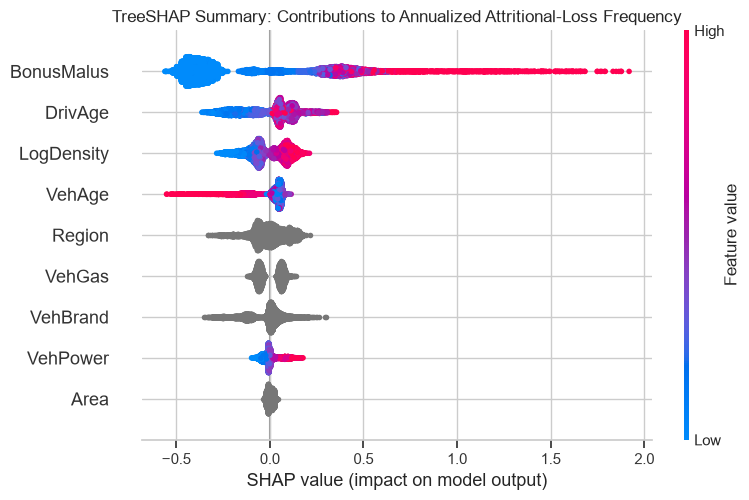

In [3]:
# Initialize TreeSHAP Explainer on Champion Frequency XGBoost booster
shap_explainer = TreeSHAPExplainer(freq_booster)
shap_explanation = shap_explainer.compute_shap_values(test_df, sample_size=SHAP_N, random_state=seed)

# Global Feature Importance Table
df_imp = shap_explainer.get_feature_importance_df()
print("=== Frequency-model Feature Importance (Mean |SHAP|) ===")
display(df_imp)

# SHAP Summary Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_explanation, show=False)
plt.title("TreeSHAP Summary: Contributions to Annualized Attritional-Loss Frequency", fontsize=12)
plt.tight_layout()
plt.show()

## 4. Ratebook Translation: Marginal Rating Relativities

### Driver Age Relativities

In [4]:
_bins, _labels = get_band(config, "driv_age_ratebook")
test_eval["DrivAge_Band"] = pd.cut(test_eval["DrivAge"], bins=_bins, labels=_labels)
rel_age = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "DrivAge_Band")
print("=== Driver Age Rating Relativities ===")
display(rel_age[["DrivAge_Band", "Policies", "Exposure_Pct", "GLM_Relativity", "XGB_Relativity"]])

=== Driver Age Rating Relativities ===


,DrivAge_Band,Policies,Exposure_Pct,GLM_Relativity,XGB_Relativity
0,18-25 (Young),7935,4.604504,2.141181,2.096006
1,26-35,29892,19.283253,1.056359,1.064110
2,36-50,50589,37.110184,0.951026,0.954033
3,51-65,33926,26.735339,0.940381,0.912465
4,66+ (Senior),13261,12.266720,0.761144,0.817664


### Bonus-Malus Relativities

In [5]:
_bins, _labels = get_band(config, "bonus_malus_ratebook")
test_eval["BonusMalus_Band"] = pd.cut(test_eval["BonusMalus"], bins=_bins, labels=_labels)
rel_bm = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "BonusMalus_Band")
print("=== Bonus-Malus Rating Relativities ===")
display(rel_bm[["BonusMalus_Band", "Policies", "Exposure_Pct", "GLM_Relativity", "XGB_Relativity"]])

=== Bonus-Malus Rating Relativities ===


,BonusMalus_Band,Policies,Exposure_Pct,GLM_Relativity,XGB_Relativity
0,50 (Max Bonus),76811,62.881628,0.743421,0.688238
1,51-65,25028,17.488482,0.867165,1.137947
2,66-80,17377,10.528799,1.331469,1.473033
3,81-100 (Base),14861,8.130121,2.297466,2.050593
4,101-150,1485,0.945056,5.035704,4.695808
5,>150 (Severe Malus),41,0.025913,24.333871,7.827246


### Vehicle Age Relativities

In [6]:
_bins, _labels = get_band(config, "veh_age_ratebook")
test_eval["VehAge_Band"] = pd.cut(test_eval["VehAge"], bins=_bins, labels=_labels)
rel_veh = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "VehAge_Band")
print("=== Vehicle Age Rating Relativities ===")
display(rel_veh[["VehAge_Band", "Policies", "Exposure_Pct", "GLM_Relativity", "XGB_Relativity"]])

=== Vehicle Age Rating Relativities ===


,VehAge_Band,Policies,Exposure_Pct,GLM_Relativity,XGB_Relativity
0,0 (Brand New),11545,4.704233,1.028577,1.009928
1,1-4,44893,31.422585,1.042310,1.006086
2,5-9,34420,27.983703,1.076404,1.062535
3,10-14,29661,23.815099,0.982006,1.005110
4,15+ (Old),15084,12.074381,0.737174,0.825282


### Geographic Area Relativities

In [7]:
rel_area = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "Area")
print("=== Geographic Area Rating Relativities ===")
display(rel_area[["Area", "Policies", "Exposure_Pct", "GLM_Relativity", "XGB_Relativity"]])

=== Geographic Area Rating Relativities ===


,Area,Policies,Exposure_Pct,GLM_Relativity,XGB_Relativity
0,A,20744,17.286538,0.721012,0.743772
1,B,15216,12.120129,0.820390,0.844714
2,C,38208,28.897271,0.881555,0.908176
3,D,30553,21.693691,1.170769,1.150341
4,E,27285,17.684232,1.379385,1.297803
5,F,3597,2.318139,1.003726,1.188507
